# What are the optimal skills for Data Analysts?

## Methodology
1. Group skills to determine median salary and likelihood of being in a job posting.
2. Visualise median salary vs percent skill demand.
3. Determine if certain technologies are more prevalent.

## Data Preparation

In [1]:
#Import libraries
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt
from adjustText import adjust_text

#Load dataset
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

#Data cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

#Focus on UK jobs and remove rows with no annual salary data
df_uk = df[(df['job_country'] == 'United Kingdom')].dropna(subset='salary_year_avg').copy()

#Convert from USD to GBP
df_uk['salary_year_gbp'] = (df_uk['salary_year_avg']*0.75)
df_uk.head(3)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,salary_year_gbp
1107,Data Scientist,"Data Scientist, Customer AI Engineering","London, UK",via Ai-Jobs.net,Full-time,False,United Kingdom,2023-06-20 13:12:50,False,False,United Kingdom,year,157500.0,NaN,Tractable,"[python, numpy, pandas, scikit-learn]","{'libraries': ['numpy', 'pandas', 'scikit-lear...",118125.00
2602,Data Analyst,Admin & Data Analyst,United Kingdom,via Ai-Jobs.net,Full-time,False,United Kingdom,2023-02-10 13:55:49,False,False,United Kingdom,year,51014.0,NaN,Catch22,"[excel, word, outlook]","{'analyst_tools': ['excel', 'word', 'outlook']}",38260.50
9778,Senior Data Analyst,Workday HCM Senior Data Analyst (18 month FTC),"London, UK",via Ai-Jobs.net,Contractor,False,United Kingdom,2023-07-10 13:36:15,True,False,United Kingdom,year,111175.0,NaN,WPP,"[vba, python, r, oracle, sap, excel]","{'analyst_tools': ['sap', 'excel'], 'cloud': [...",83381.25


In [7]:
df_da = df_uk[df_uk['job_title_short'] == 'Data Analyst']
df_da_explode = df_da.explode('job_skills')
df_da_explode.head(3)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,salary_year_gbp
2602,Data Analyst,Admin & Data Analyst,United Kingdom,via Ai-Jobs.net,Full-time,False,United Kingdom,2023-02-10 13:55:49,False,False,United Kingdom,year,51014.0,NaN,Catch22,excel,"{'analyst_tools': ['excel', 'word', 'outlook']}",38260.5
2602,Data Analyst,Admin & Data Analyst,United Kingdom,via Ai-Jobs.net,Full-time,False,United Kingdom,2023-02-10 13:55:49,False,False,United Kingdom,year,51014.0,NaN,Catch22,word,"{'analyst_tools': ['excel', 'word', 'outlook']}",38260.5
2602,Data Analyst,Admin & Data Analyst,United Kingdom,via Ai-Jobs.net,Full-time,False,United Kingdom,2023-02-10 13:55:49,False,False,United Kingdom,year,51014.0,NaN,Catch22,outlook,"{'analyst_tools': ['excel', 'word', 'outlook']}",38260.5


In [14]:
df_skills = df_da_explode.groupby('job_skills')['salary_year_avg'].agg(['count','median']).sort_values('count',ascending=False)
df_skills.rename(columns={'count': 'skill_count', 'median': 'median_salary'}, inplace=True)
df_skills

,skill_count,median_salary
job_skills,,
sql,33,98500.0
excel,29,75550.0
python,25,89100.0
tableau,13,100500.0
r,9,77017.5
...,...,...
shell,1,156500.0
terminal,1,53014.0
tensorflow,1,177283.0


In [20]:
#calculate the prevalence of skills
job_count = len(df_da)
df_skills['skill_perc'] = df_skills['skill_count']/job_count*100
df_skills

,skill_count,median_salary,skill_perc
job_skills,,,
sql,33,98500.0,45.833333
excel,29,75550.0,40.277778
python,25,89100.0,34.722222
tableau,13,100500.0,18.055556
r,9,77017.5,12.500000
...,...,...,...
shell,1,156500.0,1.388889
terminal,1,53014.0,1.388889
tensorflow,1,177283.0,1.388889


In [59]:
#filter for skills in >5% of job posts
df_high_skills = df_skills[df_skills['skill_perc']>=5]
df_high_skills

,skill_count,median_salary,skill_perc
job_skills,,,
sql,33,98500.0,45.833333
excel,29,75550.0,40.277778
python,25,89100.0,34.722222
tableau,13,100500.0,18.055556
r,9,77017.5,12.500000
go,9,71000.0,12.500000
sas,8,80007.0,11.111111
power bi,7,89100.0,9.722222
looker,6,96012.5,8.333333


In [62]:
#To categorise each skill, use the job_type_skills column
df_technology = df_uk['job_type_skills'].copy()

#Drop duplicates and NAs
df_technology.drop_duplicates(inplace=True)
df_technology.dropna(inplace=True)

#Combine the dictionaries into one
tech_dict = {}
for row in df_technology:
    row_dict = ast.literal_eval(row) #convert string to dictionary
    for key, value in row_dict.items():
        if key in tech_dict:
            tech_dict[key] += value #if the key already exists add value to the existing key
        else:
            tech_dict[key] = value #if key does not exist in tech_dict, add key and value

#remove duplicates by converting values to set then back to list
for key, value in tech_dict.items():
    tech_dict[key] = list(set(value))

tech_dict

{'libraries': ['matplotlib',
  'spark',
  'pandas',
  'plotly',
  'airflow',
  'seaborn',
  'graphql',
  'pyspark',
  'kafka',
  'jupyter',
  'hadoop',
  'scikit-learn',
  'spring',
  'numpy',
  'pytorch',
  'tensorflow',
  'gdpr',
  'opencv',
  'keras'],
 'programming': ['mongo',
  'nosql',
  'perl',
  'sql',
  'julia',
  'c#',
  'go',
  'bash',
  'vba',
  'ruby',
  'mongodb',
  'python',
  'javascript',
  't-sql',
  'assembly',
  'c',
  'powershell',
  'matlab',
  'java',
  'clojure',
  'rust',
  'typescript',
  'c++',
  'scala',
  'css',
  'php',
  'golang',
  'shell',
  'r',
  'html',
  'sas'],
 'analyst_tools': ['outlook',
  'cognos',
  'qlik',
  'alteryx',
  'word',
  'ssrs',
  'ssis',
  'sharepoint',
  'looker',
  'sas',
  'powerpoint',
  'sheets',
  'excel',
  'tableau',
  'power bi',
  'dax',
  'sap'],
 'cloud': ['aws',
  'redshift',
  'azure',
  'gcp',
  'aurora',
  'oracle',
  'firebase',
  'databricks',
  'snowflake',
  'bigquery'],
 'databases': ['dynamodb',
  'firebase',


In [101]:
#Convert this dictionary to a dataframe
df_tech = pd.DataFrame(list(tech_dict.items()), columns=['technology', 'skills'])

#explode the skills
df_tech = df_tech.explode('skills')

#merge with df_high_skills
df_tech_skills = df_high_skills.merge(df_tech, left_on='job_skills', right_on='skills')

#Set technology to title case and remove underscores
df_tech_skills['technology'] = df_tech_skills['technology'].apply(lambda x: x.title())
df_tech_skills['technology'] = df_tech_skills['technology'].apply(lambda x: x.replace('_',' '))

df_tech_skills


,skill_count,median_salary,skill_perc,technology,skills
0,33,98500.0,45.833333,Programming,sql
1,29,75550.0,40.277778,Analyst Tools,excel
2,25,89100.0,34.722222,Programming,python
3,13,100500.0,18.055556,Analyst Tools,tableau
4,9,77017.5,12.500000,Programming,r
5,9,71000.0,12.500000,Programming,go
6,8,80007.0,11.111111,Programming,sas
7,8,80007.0,11.111111,Analyst Tools,sas
8,7,89100.0,9.722222,Analyst Tools,power bi
9,6,96012.5,8.333333,Analyst Tools,looker


## Plot Data

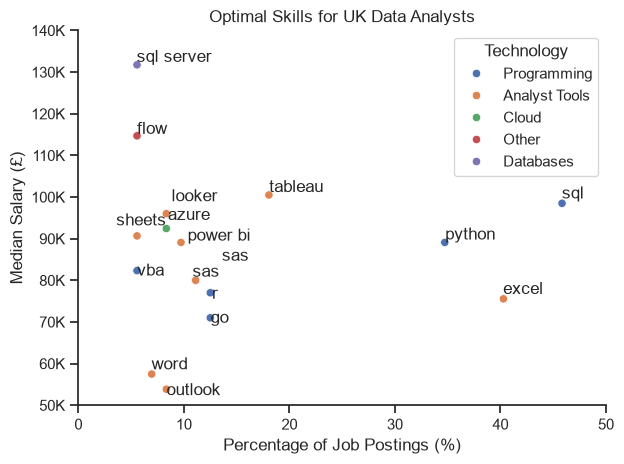

In [109]:
sns.scatterplot(data = df_tech_skills,x='skill_perc',y='median_salary',hue='technology')
sns.despine()
sns.set_theme(style='ticks')

#Prepare text labels
texts = []
for i, txt in enumerate(df_tech_skills.index):
    texts.append(plt.text(df_tech_skills['skill_perc'].iloc[i], df_tech_skills['median_salary'].iloc[i], df_tech_skills['skills'].iloc[i]))
adjust_text(texts)

#Axis customisation
plt.title('Optimal Skills for UK Data Analysts')
plt.xlabel('Percentage of Job Postings (%)')
plt.ylabel('Median Salary (£)')
plt.xlim(0,50)
plt.ylim(50_000,140_000)
ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _ : f'{int(y/1000)}K'))

#Legend customisation
plt.legend(title='Technology', loc='upper right')

plt.tight_layout()
plt.savefig('Figures/Optimal_Skills_For_Data_Analysts.png', bbox_inches='tight')
plt.show()